# L10a Advanced: How Accurate Are Greeks Computed on a Binomial Tree?
In the [L10a lecture](../../CHEME-5660-L10a-Lecture-American-Derivatives-Greeks-Fall-2026.ipynb), we estimated each Greek by repricing the contract on the CRR tree with one input moved up and down by a step $\epsilon$. How accurate are these estimates, and when does a different tree help?

> __Learning Objectives:__
>
> By the end of this notebook, you should be able to:
> * __Measure the error of tree Greeks:__ Compute central-difference Greeks for a European call on the CRR tree and compare them with the Black–Scholes–Merton values. Explain why a step smaller than the spacing between the premium's corners gives the wrong Gamma.
> * __Build the Leisen–Reimer tree:__ Construct its up and down factors from the Peizer–Pratt inversion and check the risk-neutral condition. Compare its premium and Greeks with the CRR tree as the number of tree steps grows.
> * __Compute the Greeks of an American put:__ Refine the Leisen–Reimer tree until the American put's premium and Greeks stop changing. Plot Delta and Gamma against the share price and locate the early-exercise boundary.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file of the L10a folder, two folders up, and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "..", "..", "Include.jl")); # the L10a Include.jl, two folders up

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
To start, load an end-of-day options chain from the course's options archive, which holds the chains of 31 tickers captured after each close from April 13 to October 8, 2026. [The `MyOptionsEODChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsEODChainDataSet) returns the chain for one ticker, trading session, and expiration, with the share price on that session. Store the data in the `metadata::Dict{String,Any}` and `optionschain::DataFrame` variables.

In [2]:
ticker = "NVDA"; # underlying ticker: any of the 31 tickers in the archive
quote_date = Date(2026, 10, 8); # trading session of the quotes (the archive's last session)
target_dte = 45; # days to expiration target, one of the archive's ladder values (2, 7, 14, 30, 45)

metadata, optionschain = let

    # initialize: the first call downloads the archive (about 112 MB) -
    session = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date); # every expiration that session

    # keep the expiration matched to the target -
    expiration = filter(:target_dte => ==(target_dte), session.data).expiration |> first;
    options_dataset = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date, expiration = expiration);
    metadata = options_dataset.metadata;
    optionschain = options_dataset.data;

    (metadata, optionschain) # return
end;

### Constants and contracts
Next, let's set the constants. The risk-free rate is the yield of the 13-week Treasury bill on the quote date, converted to continuous compounding. We pick one call and one put at the money: the listed strike nearest the share price that has an implied volatility in the archive.

Task 1 and Task 2 compare tree Greeks with the Black–Scholes–Merton formulas, so we build the call as [a `MyEuropeanCallContractModel` instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyEuropeanCallContractModel). Task 3 needs early exercise, so we build the put as [a `MyAmericanPutContractModel` instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanPutContractModel):

In [3]:
Sₒ = metadata["underlying_close"]; # share price at the close of the quote date (USD/share)
DTE = metadata["DTE"]; # days to expiration (days)
T = DTE/365; # time to expiration (years)
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-08, U.S. Treasury Daily Treasury Bill Rates; update it if you change quote_date
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)

# at the money: the listed strike nearest the share price that has an implied volatility -
function at_the_money(type::String)::DataFrameRow
    df = filter(r -> r.type == type && !ismissing(r.implied_vol), optionschain);
    return df[argmin(abs.(df.strike .- Sₒ)), :];
end
call_row = at_the_money("call");
put_row = at_the_money("put");

# contract models: a European call for Tasks 1 and 2, an American put for Task 3 -
european_call = build(MyEuropeanCallContractModel, (K = call_row.strike, IV = call_row.implied_vol,
    DTE = T, sense = 1, copy = 1));
american_put = build(MyAmericanPutContractModel, (K = put_row.strike, IV = put_row.implied_vol,
    DTE = T, sense = 1, copy = 1));

let
    df = DataFrame(
        quantity = ["ticker", "quote date", "expiration", "share price Sₒ", "time to expiration T",
            "risk-free rate gᵧ", "call strike K", "call implied volatility σ", "put strike K", "put implied volatility σ"],
        value = Any[metadata["ticker"], metadata["quote_date"], metadata["expiration_date"], Sₒ, round(T, digits = 4),
            round(gᵧ, digits = 4), european_call.K, european_call.IV, american_put.K, american_put.IV],
        units = ["", "", "", "USD/share", "years", "1/year", "USD/share", "1/sqrt(year)", "USD/share", "1/sqrt(year)"]);
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 --------------------------- ------------ --------------
  quantity                         value   units        
 --------------------------- ------------ --------------
  ticker                            NVDA
  quote date                  2026-10-08
  expiration                  2026-11-20
  share price Sₒ                  230.57   USD/share
  time to expiration T            0.1178   years
  risk-free rate gᵧ               0.0413   1/year
  call strike K                    230.0   USD/share
  call implied volatility σ       0.3521   1/sqrt(year)
  put strike K                     230.0   USD/share
  put implied volatility σ          0.37   1/sqrt(year)
 --------------------------- ------------ --------------


___

## Task 1: CRR Greeks for a European Call
In this task, we'll compute Delta and Gamma of the European call on the CRR tree and compare them with the Black–Scholes–Merton values.

For a European call on a share that pays no dividend, differentiating the L9a Black–Scholes–Merton formula gives each Greek in closed form:
$$
\begin{align*}
\Delta_{c} & = N(d_{+})\\
\Gamma_{c} & = \frac{\phi(d_{+})}{S\sigma\sqrt{T}}\\
\Theta_{c} & = -\frac{S\phi(d_{+})\sigma}{2\sqrt{T}} - g_{y}Ke^{-g_{y}T}N(d_{-})\\
\nu_{c} & = S\phi(d_{+})\sqrt{T}\\
\rho_{c} & = KTe^{-g_{y}T}N(d_{-})
\end{align*}
$$
where $N$ and $\phi$ are the standard normal CDF and density, $d_{\pm}$ are the L9a quantities at the share price $S$, and $T$ is the time to expiration. $\Theta_{c}$ is the change per year of calendar time, as in the lecture.

Let's code the formulas and evaluate them at $S(0)$:

In [4]:
function bsm_call(S::Float64, K::Float64, σ::Float64, g::Float64, T::Float64)::NamedTuple

    # L9a quantities -
    d₊ = (log(S/K) + (g + σ^2/2)*T)/(σ*sqrt(T));
    d₋ = d₊ - σ*sqrt(T);
    N = Normal(); # standard normal: cdf(N, x) is N(x), pdf(N, x) is ϕ(x)

    # premium and the five Greeks -
    return (premium = S*cdf(N, d₊) - K*exp(-g*T)*cdf(N, d₋),
        delta = cdf(N, d₊),
        gamma = pdf(N, d₊)/(S*σ*sqrt(T)),
        theta = -S*pdf(N, d₊)*σ/(2*sqrt(T)) - g*K*exp(-g*T)*cdf(N, d₋),
        vega = S*pdf(N, d₊)*sqrt(T),
        rho = K*T*exp(-g*T)*cdf(N, d₋));
end
bsm = bsm_call(Sₒ, european_call.K, european_call.IV, gᵧ, T);

let
    df = DataFrame(quantity = ["premium", "Delta", "Gamma", "Theta", "Vega", "Rho"],
        value = collect(values(bsm)),
        units = ["USD/share", "share/share", "1/(USD/share)", "USD/share per year", "USD/share per unit σ",
            "USD/share per unit gᵧ"]);
    pretty_table(df; column_labels = ["Black–Scholes–Merton", "value", "units"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.6f", [2])], fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ---------------------- ------------ -----------------------
  Black–Scholes–Merton        value   units                 
 ---------------------- ------------ -----------------------
  premium                 11.932457   USD/share
  Delta                    0.548216   share/share
  Gamma                    0.014212   1/(USD/share)
  Theta                  -51.561428   USD/share per year
  Vega                    31.341033   USD/share per unit σ
  Rho                     13.485459   USD/share per unit gᵧ
 ---------------------- ------------ -----------------------


Before we compute Greeks on the tree, let's look at how the CRR premium changes with the share price. We price the call on a 51-step tree with [the `binomial_premium(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.binomial_premium) at share prices within 10% of $S(0)$. At each share price, we estimate the slope with a tiny step $\epsilon$, 0.01% of the share price:

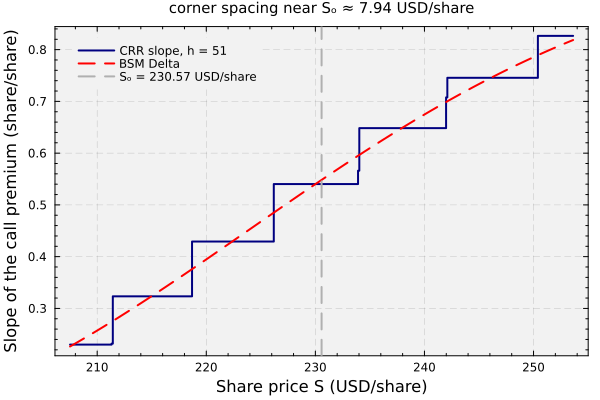

In [5]:
let

    # initialize -
    h = 51; # number of tree steps
    σ = european_call.IV;
    corner_spacing = (exp(2*σ*sqrt(T/h)) - 1)*Sₒ; # distance between neighboring corners near Sₒ (USD/share)
    crr(S) = binomial_premium(european_call; method = :crr, h = h, T = T, σ = σ, Sₒ = S, μ = gᵧ);

    # slope of the CRR premium with a tiny step, and the BSM Delta -
    S_range = range(0.9*Sₒ, stop = 1.1*Sₒ, length = 401) |> collect;
    ϵ = 1e-4*Sₒ; # tiny step (USD/share)
    crr_slope = [(crr(S + ϵ) - crr(S - ϵ))/(2ϵ) for S ∈ S_range];
    bsm_delta = [bsm_call(S, european_call.K, σ, gᵧ, T).delta for S ∈ S_range];

    # plot -
    plot(S_range, crr_slope, label = "CRR slope, h = $(h)", lw = 2, c = :navy, linetype = :steppost);
    plot!(S_range, bsm_delta, label = "BSM Delta", lw = 2, c = :red, ls = :dash);
    vline!([Sₒ], lw = 2, c = :gray69, ls = :dash, label = "Sₒ = $(Sₒ) USD/share");
    plot!(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, grid = :both, gridstyle = :dash, legend = :topleft,
        title = "corner spacing near Sₒ ≈ $(round(corner_spacing, digits = 2)) USD/share", titlefontsize = 10);
    xlabel!("Share price S (USD/share)");
    ylabel!("Slope of the call premium (share/share)");
end

__Why a staircase?__ The CRR factors $u=e^{\sigma\sqrt{\Delta t}}$ and $d=e^{-\sigma\sqrt{\Delta t}}$, with $\Delta t=T/h$, do not depend on the share price. Every terminal share price $S\,u^{j}d^{h-j}$ therefore moves in proportion to $S$:

* __Straight pieces:__ The premium is the discounted, $q$-weighted sum of the terminal payoffs $\max(S\,u^{j}d^{h-j}-K,0)$. Each payoff is a straight line in $S$ with one corner, where its node crosses the strike, so the premium is straight between corners.
* __Corner spacing:__ Neighboring corners are a factor $u/d=e^{2\sigma\sqrt{\Delta t}}$ apart, about $2\sigma\sqrt{\Delta t}\,S$ in share price. The plot's title gives this spacing on the 51-step tree.
* __Effect on the Greeks:__ A central difference whose step stays between two corners returns the slope of one straight piece for Delta, and zero for Gamma. Adding tree steps moves the corners closer together but never removes them.

So the step $\epsilon$ must span the corners. Let's compute Delta and Gamma on a 201-step tree with [the `binomial_greeks(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.binomial_greeks), with steps from 0.1% to 5% of the share price:

In [6]:
let

    # initialize -
    h = 201; # number of tree steps
    σ = european_call.IV;
    corner_spacing = (exp(2*σ*sqrt(T/h)) - 1)*Sₒ; # (USD/share)
    df = DataFrame();

    # Delta and Gamma errors against BSM for each step ϵ -
    for fraction ∈ [0.001, 0.005, 0.01, 0.02, 0.05]
        ϵ = fraction*Sₒ;
        g = binomial_greeks(european_call; method = :crr, h = h, T = T, σ = σ, Sₒ = Sₒ, μ = gᵧ, spot_bump = ϵ);
        push!(df, (percent = 100*fraction, ϵ = ϵ, corners = ϵ/corner_spacing,
            delta_error = g.delta - bsm.delta, gamma_error = g.gamma - bsm.gamma));
    end

    pretty_table(df; column_labels = ["ϵ (% of Sₒ)", "ϵ (USD/share)", "ϵ / corner spacing",
            "Delta error", "Gamma error (1/(USD/share))"],
        title = "201-step CRR tree, BSM Gamma = $(round(bsm.gamma, sigdigits = 4)) per USD/share",
        formatters = [fmt__printf("%.1f", [1]), fmt__printf("%.3f", [2, 3]), fmt__printf("%.5f", [4, 5])],
        fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: halfway between two corners, a step inside one straight piece gives a CRR Gamma of zero -
    a = σ*sqrt(T/h); # with odd h, the corners sit at K⋅exp(m⋅a) for odd m
    S_mid = european_call.K*exp(2a*round(log(Sₒ/european_call.K)/(2a))); # halfway between the corners nearest Sₒ
    tiny = binomial_greeks(european_call; method = :crr, h = h, T = T, σ = σ, Sₒ = S_mid, μ = gᵧ, spot_bump = 0.5*a*S_mid);
    @assert abs(tiny.gamma) < 1e-8 "a step inside one straight piece should give zero Gamma"
end

                      201-step CRR tree, BSM Gamma = 0.01421 per USD/share
 ------------- --------------- -------------------- ------------- -----------------------------
  ϵ (% of Sₒ)   ϵ (USD/share)   ϵ / corner spacing   Delta error   Gamma error (1/(USD/share)) 
 ------------- --------------- -------------------- ------------- -----------------------------
          0.1           0.231                0.058      -0.00807                      -0.01421
          0.5           1.153                0.291      -0.00807                      -0.01421
          1.0           2.306                0.582       0.00282                      -0.00476
          2.0           4.611                1.163      -0.00150                      -0.00032
          5.0          11.529                2.908      -0.00254                      -0.00019
 ------------- --------------- -------------------- ------------- -----------------------------


__What do we see?__ For the two smallest steps, the Gamma error equals minus the BSM Gamma: the tree reports a Gamma of zero. The errors shrink once $\epsilon$ spans at least one corner. At the largest step, the Delta error grows again, because the central difference now averages the slope over a wide range of share prices.

___

## Task 2: The Leisen–Reimer Tree
In this task, we'll build the Leisen–Reimer tree, check its construction by hand, and compare its premium and Greeks with the CRR tree.

__Reference:__
* [Leisen, D. P. J.; Reimer, M. (1996). "Binomial models for option valuation – examining and improving convergence". Applied Mathematical Finance. 3 (4): 319–346. doi:10.1080/13504869600000015](https://doi.org/10.1080/13504869600000015)

Leisen and Reimer choose the risk-neutral probability first. With an odd number of tree steps $h$, they pick $q$ so that the tree's chance of finishing above the strike matches the normal probability $N(d_{-})$ in the Black–Scholes–Merton formula, using the Peizer–Pratt inversion $H$ of the binomial distribution. A second probability $q'$, built the same way from $d_{+}$, then sets the factors:
$$
\begin{align*}
H(z;h) & = \frac{1}{2}+\frac{\operatorname{sgn}(z)}{2}\sqrt{1-\exp\left[-\left(\frac{z}{h+1/3+0.1/(h+1)}\right)^{2}\left(h+\frac{1}{6}\right)\right]} && \text{Peizer–Pratt inversion}\\
q & = H(d_{-};h) && \text{risk-neutral up probability}\\
q' & = H(d_{+};h) && \text{second probability}\\
u & = e^{g_{y}\Delta t}\,\frac{q'}{q} && \text{up factor}\\
d & = e^{g_{y}\Delta t}\,\frac{1-q'}{1-q} && \text{down factor}
\end{align*}
$$
where $\Delta t=T/h$. These factors satisfy the same risk-neutral condition as the CRR factors in L9b, so one step grows the expected share price at the risk-free rate:
$$
\begin{align*}
qu+(1-q)d & = q\,e^{g_{y}\Delta t}\frac{q'}{q}+(1-q)\,e^{g_{y}\Delta t}\frac{1-q'}{1-q} && \text{substitute } u \text{ and } d\\
& = e^{g_{y}\Delta t}\left(q'+1-q'\right) && \text{cancel } q \text{ and } 1-q\\
& = e^{g_{y}\Delta t} && q'+(1-q')=1
\end{align*}
$$
Because $d_{\pm}$ depend on $S$, so do the factors. As $S$ moves, the strike stays between the two middle terminal nodes, so no node crosses it and the premium has no corners. The backward induction and the American exercise decision are the same as on the CRR tree.

Let's build the 51-step tree by hand. With a constant $q$, the number of up moves $j$ by expiration is binomial, so the European call premium is the discounted expected payoff over the terminal nodes:
$$
\mathcal{P}_{c}=e^{-g_{y}T}\sum_{j=0}^{h}\binom{h}{j}q^{j}(1-q)^{h-j}\max\left(S(0)\,u^{j}d^{h-j}-K,~0\right)
$$

In [7]:
lr_by_hand = let

    # initialize -
    h = 51; # odd number of tree steps
    K = european_call.K; σ = european_call.IV;
    Δt = T/h; # length of one tree step (years)
    d₊ = (log(Sₒ/K) + (gᵧ + σ^2/2)*T)/(σ*sqrt(T));
    d₋ = d₊ - σ*sqrt(T);

    # Peizer–Pratt inversion, probabilities, and factors -
    H(z, n) = 1/2 + (sign(z)/2)*sqrt(1 - exp(-(z/(n + 1/3 + 0.1/(n + 1)))^2*(n + 1/6)));
    q = H(d₋, h); # risk-neutral up probability
    q′ = H(d₊, h); # second probability
    u = exp(gᵧ*Δt)*(q′/q); # up factor
    d = exp(gᵧ*Δt)*((1 - q′)/(1 - q)); # down factor

    # European premium: discounted expected payoff over the terminal nodes -
    by_hand = exp(-gᵧ*T)*sum(pdf(Binomial(h, q), j)*max(Sₒ*u^j*d^(h - j) - K, 0.0) for j ∈ 0:h);
    package = binomial_premium(european_call; method = :leisen_reimer, h = h, T = T, σ = σ, Sₒ = Sₒ, μ = gᵧ);

    df = DataFrame(quantity = ["risk-neutral up probability q", "second probability q′", "up factor u", "down factor d",
            "q⋅u + (1 − q)⋅d", "exp(gᵧ⋅Δt)", "premium by hand (USD/share)", "premium, binomial_premium(...) (USD/share)",
            "premium, Black–Scholes–Merton (USD/share)"],
        value = [q, q′, u, d, q*u + (1 - q)*d, exp(gᵧ*Δt), by_hand, package, bsm.premium]);
    pretty_table(df; column_labels = ["51-step Leisen–Reimer tree", "value"], alignment = [:l, :r],
        formatters = [fmt__printf("%.8f", [2])], fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the risk-neutral condition holds, and the hand premium matches the package -
    @assert isapprox(q*u + (1 - q)*d, exp(gᵧ*Δt); rtol = 1e-12) "risk-neutral condition fails"
    @assert isapprox(by_hand, package; atol = 1e-8) "hand premium differs from binomial_premium(...)"

    (q = q, q′ = q′, u = u, d = d, premium = by_hand) # return
end;

 -------------------------------------------- -------------
  51-step Leisen–Reimer tree                         value 
 -------------------------------------------- -------------
  risk-neutral up probability q                 0.50002105
  second probability q′                         0.50844025
  up factor u                                   1.01693467
  down factor d                                 0.98325467
  q⋅u + (1 − q)⋅d                               1.00009538
  exp(gᵧ⋅Δt)                                    1.00009538
  premium by hand (USD/share)                  11.93224708
  premium, binomial_premium(...) (USD/share)   11.93224708
  premium, Black–Scholes–Merton (USD/share)    11.93245738
 -------------------------------------------- -------------


Now let's compare the two trees as the number of tree steps grows. We price the call and compute Delta and Gamma with the package's default step, $\epsilon$ equal to 1% of the share price. The CRR tree uses every number of steps from 50 to 400, and the Leisen–Reimer tree every odd number from 51 to 401:

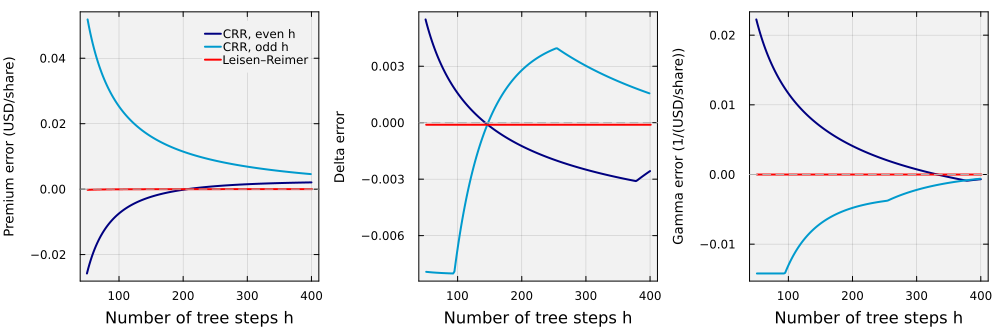

In [8]:
convergence_df = let

    # initialize -
    σ = european_call.IV;
    df = DataFrame();

    runs = [[(:crr, h) for h ∈ 50:400]; [(:leisen_reimer, h) for h ∈ 51:2:401]]; # Leisen–Reimer needs odd h
    for (method, h) ∈ runs
        premium = binomial_premium(european_call; method = method, h = h, T = T, σ = σ, Sₒ = Sₒ, μ = gᵧ);
        g = binomial_greeks(european_call; method = method, h = h, T = T, σ = σ, Sₒ = Sₒ, μ = gᵧ);
        tree = method == :crr ? (iseven(h) ? "CRR, even h" : "CRR, odd h") : "Leisen–Reimer";
        push!(df, (h = h, tree = tree, premium_error = premium - bsm.premium,
            delta_error = g.delta - bsm.delta, gamma_error = g.gamma - bsm.gamma));
    end

    df # return
end;

let
    panels = [];
    for (key, label) ∈ ((:premium_error, "Premium error (USD/share)"), (:delta_error, "Delta error"),
            (:gamma_error, "Gamma error (1/(USD/share))"))
        p = plot(xlabel = "Number of tree steps h", ylabel = label, yguidefontsize = 9,
            legend = key == :premium_error ? :topright : false); # one legend, in the first panel
        for (tree, color) ∈ (("CRR, even h", :navy), ("CRR, odd h", :deepskyblue3), ("Leisen–Reimer", :red))
            rows = filter(:tree => ==(tree), convergence_df);
            plot!(p, rows.h, rows[!, key], label = tree, lw = 2, c = color);
        end
        hline!(p, [0.0], c = :gray69, ls = :dash, label = "");
        push!(panels, p);
    end
    plot(panels..., layout = (1, 3), size = (1000, 330), left_margin = 4Plots.mm, bottom_margin = 5Plots.mm,
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent)
end

__What do we see?__ The CRR errors fall on two separate curves, one for even and one for odd numbers of tree steps, so adding a single step can change the error a lot, even its sign. With an even number of steps, the middle terminal node sits at $S(0)$, next to an at-the-money strike. With an odd number, the strike falls between two nodes. The Leisen–Reimer errors stay near zero at every number of tree steps.

How do the trees compare across all five Greeks? Let's compute them on 201-step trees with the package's default steps and convert them to the quotes a trading platform shows: Theta per day, and Vega and Rho per percentage point:

In [9]:
let

    # initialize -
    h = 201;
    σ = european_call.IV;
    crr = binomial_greeks(european_call; method = :crr, h = h, T = T, σ = σ, Sₒ = Sₒ, μ = gᵧ);
    lr = binomial_greeks(european_call; method = :leisen_reimer, h = h, T = T, σ = σ, Sₒ = Sₒ, μ = gᵧ);
    quote_scale = [1.0, 1.0, 1/365, 1/100, 1/100]; # raw derivative → displayed quote
    greek_names = [:delta, :gamma, :theta, :vega, :rho];

    df = DataFrame(greek = ["Delta", "Gamma", "Theta (per day)", "Vega (per point)", "Rho (per point)"],
        bsm = [getfield(bsm, k) for k ∈ greek_names] .* quote_scale,
        crr = [getfield(crr, k) for k ∈ greek_names] .* quote_scale,
        lr = [getfield(lr, k) for k ∈ greek_names] .* quote_scale);
    df.crr_error = df.crr .- df.bsm;
    df.lr_error = df.lr .- df.bsm;

    pretty_table(df; column_labels = ["quote", "BSM", "CRR, h = 201", "LR, h = 201", "CRR − BSM", "LR − BSM"],
        formatters = [fmt__printf("%.6f", [2, 3, 4]), fmt__printf("%.2e", [5, 6])], alignment = [:l, :r, :r, :r, :r, :r],
        fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: Leisen–Reimer Greeks are close to BSM -
    @assert all(abs.(df.lr_error) .< 1e-3) "Leisen–Reimer quotes should be within 0.001 of BSM"
end

 ------------------ ----------- -------------- ------------- ----------- -----------
  quote                    BSM   CRR, h = 201   LR, h = 201   CRR − BSM    LR − BSM 
 ------------------ ----------- -------------- ------------- ----------- -----------
  Delta               0.548216       0.551036      0.548106    2.82e-03   -1.09e-04
  Gamma               0.014212       0.009448      0.014205   -4.76e-03   -7.33e-06
  Theta (per day)    -0.141264      -0.141457     -0.141273   -1.93e-04   -8.59e-06
  Vega (per point)    0.313410       0.313865      0.313410    4.54e-04   -4.02e-07
  Rho (per point)     0.134855       0.134836      0.134855   -1.91e-05    3.63e-08
 ------------------ ----------- -------------- ------------- ----------- -----------


__What do we see?__ The CRR Gamma is the worst quote, because the default step is smaller than the corner spacing on the 201-step tree. Every Leisen–Reimer quote agrees with the BSM value to a few decimal places.

With no corners, the remaining error in the Leisen–Reimer Greeks comes from the central difference itself. Let's shrink the step $\epsilon$ on the 201-step Leisen–Reimer tree:

In [10]:
let

    # initialize -
    h = 201;
    σ = european_call.IV;
    df = DataFrame();

    for fraction ∈ [0.02, 0.01, 0.005, 0.001]
        g = binomial_greeks(european_call; method = :leisen_reimer, h = h, T = T, σ = σ, Sₒ = Sₒ, μ = gᵧ,
            spot_bump = fraction*Sₒ);
        push!(df, (percent = 100*fraction, delta_error = g.delta - bsm.delta, gamma_error = g.gamma - bsm.gamma));
    end

    pretty_table(df; column_labels = ["ϵ (% of Sₒ)", "Delta error", "Gamma error (1/(USD/share))"],
        formatters = [fmt__printf("%.1f", [1]), fmt__printf("%.2e", [2, 3])],
        fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: unlike CRR, a small step gives an accurate Gamma -
    @assert abs(last(df).gamma_error) < 1e-4*bsm.gamma "a small step should give a Leisen–Reimer Gamma within 0.01% of BSM"
end

 ------------- ------------- -----------------------------
  ϵ (% of Sₒ)   Delta error   Gamma error (1/(USD/share)) 
 ------------- ------------- -----------------------------
          2.0     -4.35e-04                     -2.95e-05
          1.0     -1.09e-04                     -7.33e-06
          0.5     -2.73e-05                     -1.79e-06
          0.1     -1.02e-06                     -1.26e-08
 ------------- ------------- -----------------------------


__What do we see?__ Each time the step is halved, the errors fall by about a factor of four, the behavior of a central difference on a smooth function. On the Leisen–Reimer tree, a smaller step gives a better Greek, which is the opposite of what we saw on the CRR tree.

___

## Task 3: The Greeks of an American Put
In this task, we'll compute the Greeks of the American put by refining the Leisen–Reimer tree, then plot Delta and Gamma against the share price.

With no formula to check against, we double the number of tree steps until the premium and the Greeks stop changing:

In [11]:
refinement_df = let

    # initialize -
    σ = american_put.IV;
    df = DataFrame();

    for h ∈ [101, 201, 401, 801, 1601, 3201]
        premium = binomial_premium(american_put; method = :leisen_reimer, h = h, T = T, σ = σ, Sₒ = Sₒ, μ = gᵧ);
        g = binomial_greeks(american_put; method = :leisen_reimer, h = h, T = T, σ = σ, Sₒ = Sₒ, μ = gᵧ);
        push!(df, (h = h, premium = premium, delta = g.delta, gamma = g.gamma, theta_day = g.theta/365));
    end
    df.change = [missing; diff(df.premium)]; # change in premium from the previous row

    pretty_table(select(df, :h, :premium, :change, :delta, :gamma, :theta_day);
        column_labels = ["tree steps h", "premium (USD/share)", "change (USD/share)", "Delta", "Gamma",
            "Theta (USD/share per day)"],
        formatters = [fmt__printf("%.6f", [2, 4, 5, 6]), fmt__printf("%.2e", [3])],
        fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the premium has settled to well under a cent -
    @assert abs(last(df.change)) < 1e-3 "the American put premium has not settled"

    df # return
end;

 -------------- --------------------- -------------------- ----------- ---------- ---------------------------
  tree steps h   premium (USD/share)   change (USD/share)       Delta      Gamma   Theta (USD/share per day) 
 -------------- --------------------- -------------------- ----------- ---------- ---------------------------
           101             10.882284              missing   -0.455936   0.013727                   -0.123848
           201             10.881314            -9.70e-04   -0.455974   0.013722                   -0.123844
           401             10.880745            -5.69e-04   -0.455985   0.013727                   -0.123833
           801             10.880462            -2.83e-04   -0.455994   0.013728                   -0.123830
          1601             10.880319            -1.44e-04   -0.455997   0.013728                   -0.123828
          3201             10.880245            -7.40e-05   -0.455999   0.013729                   -0.123827
 -------------- 

__What do we see?__ The premium settles to well under a cent, and Delta, Gamma, and Theta agree to five decimal places at the two largest trees. The change roughly halves each time the number of steps doubles. This is slower than for the European call, because the exercise boundary falls between the nodes.

Where does early exercise show up in the Greeks? Below some share price $S^{\star}$, exercising the put is worth more than holding it, so the American premium equals the payoff $K-S$. There, Delta is $-1$ and Gamma is $0$. We find $S^{\star}$ on the 801-step tree by bisection, as the largest share price at which the premium equals the payoff.

Then we compute Delta and Gamma on 201-step CRR and Leisen–Reimer trees from below $S^{\star}$ to above the strike. For comparison, the European put has $\Delta_{p}=N(d_{+})-1$ from put–call parity (L9a), and the same Gamma as the call:

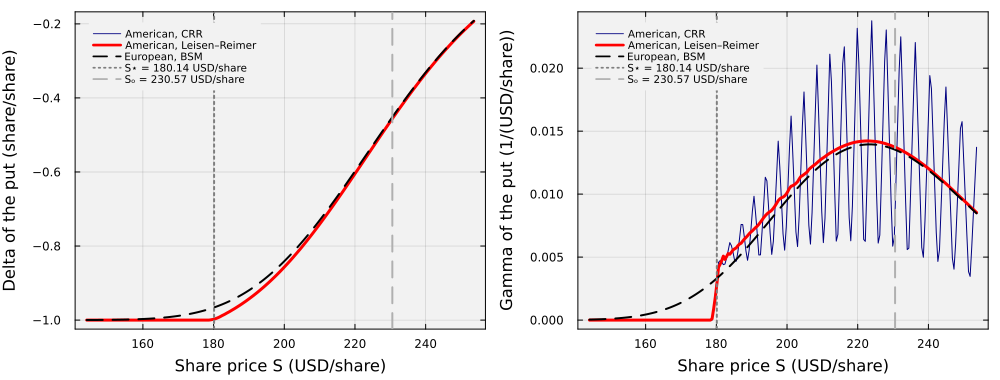

In [12]:
S_boundary = let # exercise boundary S⋆ (USD/share)

    # premium minus payoff: zero where the holder exercises today -
    K = american_put.K; σ = american_put.IV;
    excess(S) = binomial_premium(american_put; method = :leisen_reimer, h = 801, T = T, σ = σ, Sₒ = S, μ = gᵧ) - (K - S);

    # bisection: lo starts in the exercise region, hi above it -
    lo, hi = 0.3*K, K;
    for _ ∈ 1:50
        mid = (lo + hi)/2;
        excess(mid) < 1e-9 ? (lo = mid) : (hi = mid);
    end

    # checks: lo is still in the exercise region and hi is not, so S⋆ lies between them -
    @assert excess(lo) < 1e-9 && excess(hi) > 1e-9 "the bracket lost the exercise boundary"

    lo # return
end;

let

    # initialize -
    K = american_put.K; σ = american_put.IV;
    S_range = range(0.8*S_boundary, stop = 1.1*max(K, Sₒ), length = 241) |> collect;
    df = DataFrame();

    # American put on both trees, European put from BSM -
    for S ∈ S_range
        crr = binomial_greeks(american_put; method = :crr, h = 201, T = T, σ = σ, Sₒ = S, μ = gᵧ);
        lr = binomial_greeks(american_put; method = :leisen_reimer, h = 201, T = T, σ = σ, Sₒ = S, μ = gᵧ);
        eu = bsm_call(S, K, σ, gᵧ, T); # put: Delta = call Delta − 1, same Gamma
        push!(df, (S = S, crr_delta = crr.delta, crr_gamma = crr.gamma, lr_delta = lr.delta, lr_gamma = lr.gamma,
            eu_delta = eu.delta - 1, eu_gamma = eu.gamma));
    end

    # plot -
    panels = [];
    for (name, label) ∈ (("delta", "Delta of the put (share/share)"), ("gamma", "Gamma of the put (1/(USD/share))"))
        p = plot(df.S, df[!, "crr_" * name], label = "American, CRR", lw = 1, c = :navy);
        plot!(p, df.S, df[!, "lr_" * name], label = "American, Leisen–Reimer", lw = 3, c = :red);
        plot!(p, df.S, df[!, "eu_" * name], label = "European, BSM", lw = 2, c = :black, ls = :dash);
        vline!(p, [S_boundary], lw = 2, c = :gray50, ls = :dot, label = "S⋆ = $(round(S_boundary, digits = 2)) USD/share");
        vline!(p, [Sₒ], lw = 2, c = :gray69, ls = :dash, label = "Sₒ = $(Sₒ) USD/share");
        xlabel!(p, "Share price S (USD/share)");
        ylabel!(p, label);
        push!(panels, p);
    end
    plot(panels..., layout = (1, 2), size = (1000, 380), left_margin = 4Plots.mm, bottom_margin = 5Plots.mm,
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        legend = :topleft, legendfontsize = 7)
end

__What do we see?__ The CRR Gamma swings widely as the share price changes, while the Leisen–Reimer curves are smooth. Below $S^{\star}$, the American Delta sits at $-1$ and its Gamma at $0$, while the European put keeps a positive Gamma there. Just above $S^{\star}$, the American Gamma jumps up from zero.

### Discussion
1. __Why does the exercise boundary sit below the strike?__ Holding a put that is only a little in the money keeps the chance of a larger payoff later. How far must the share price fall before receiving $K$ today beats waiting?
2. __Which tree would you use to report the Greeks of a long-dated American put?__ Use Task 2 and Task 3 to justify the choice of tree, the number of tree steps, and the step $\epsilon$.

___

## Summary
In this notebook, we checked Greeks computed on binomial trees against the Black–Scholes–Merton values, built the Leisen–Reimer tree by hand, and computed the Greeks of an American put.

> __Key Takeaways:__
>
> * __The CRR premium has corners in the share price:__ The CRR factors do not depend on the share price, so the premium is a straight line between the corners where a terminal node crosses the strike. A central-difference step that stays between two corners reports a Gamma of zero, and the errors change from even to odd numbers of tree steps.
> * __The Leisen–Reimer tree removes the corners:__ Its factors move with the share price, so the premium is smooth and its Greeks match the Black–Scholes–Merton values closely at every number of tree steps. The remaining error comes from the central difference and falls about fourfold when the step is halved.
> * __Early exercise shows up in Delta and Gamma:__ Below the exercise boundary, the American put's premium equals its payoff, so Delta is minus one and Gamma is zero. With no closed form to check against, we refine the tree until the premium and the Greeks stop changing.

Before reporting a Greek computed on a tree, change the step and the number of tree steps and check that the number holds still. Changing `ticker` in the data cell repeats every check for another contract.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___